# Comparación de modelos: explorar, decidir y comprobar

Este notebook desarrolla el proyecto completo con explicaciones para principiantes.
Cada bloque sigue una pregunta, muestra evidencia y explica qué decisión permite tomar.
Puedes leerlo de arriba abajo: **las explicaciones forman parte de la solución**.

**Qué aprenderás:** distinguir identificadores de mediciones; revisar faltantes y extremos;
leer correlaciones y mapas de calor; interpretar categorías; comparar tratamientos;
y justificar una recomendación entre regresión logística, KNN y árbol.

**Qué significa “mejor” aquí:** la mejor configuración entre alternativas justificadas y
evaluadas con un protocolo fijo. No existe una preparación que garantice la mejor puntuación
posible en todos los modelos. No se promete alcanzar el 93 % de otra persona: primero habría
que conocer su métrica, sus registros y su evaluación.

**Cómo usarlo:** lee el texto anterior y posterior a cada salida. Para reproducirlo, utiliza
el entorno del curso y ejecuta **Restart & Run All**. La búsqueda de configuraciones es la
parte más lenta. Los imports están reunidos al principio y las semillas son 42.

**Primera lectura en cuatro paradas.** En la sección 6 busca el colesterol de Switzerland.
En la 7 observa el mismo colesterol antes y después de la transformación.
En la 8 sigue el cruce de edad y frecuencia cardíaca desde el mapa hasta los puntos.
En la 11 compara «Ausencia explícita» con «Sin ca» para ver qué pasó al quitar esa medición.
Puedes leer las figuras y sus comentarios primero y volver al código después.

El archivo de partida de esta copia se conserva en
<code>recursos_comparacion/copia_antes_de_reorganizar.ipynb</code>.


## Consigna del curso

# Capítulo 5 · Proyecto 1: comparación de modelos

> ¿Qué modelo recomendarías para clasificar la presencia de enfermedad cardiaca y qué resultados respaldan tu elección?

Utiliza el dataset [UCI Heart Disease de Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data), archivo `heart_disease_uci.csv`, y documenta tu trabajo en un notebook reproducible.

## Etapa 1: limpieza y preparación

1. Identifica los valores faltantes y los valores inválidos, decide cómo tratarlos y justifica brevemente tu decisión.
2. Explora los posibles outliers y explica si los conservarás o aplicarás algún tratamiento.
3. Prepara las variables numéricas y categóricas. Crea el objetivo binario (**target**) a partir de `num`: **target = 0 si num = 0** (ausencia de enfermedad) y **target = 1 si num es 1, 2, 3 o 4** (presencia de enfermedad). Excluye tanto `num` como el target de las entradas del modelo.

## Etapa 2: entrenamiento y comparación

1. Separa los datos en entrenamiento, validación y prueba, usando las mismas particiones para todos los modelos y `random_state=42`. Ajusta la imputación y el escalado únicamente con entrenamiento.
2. Entrena **regresión logística, KNN y árbol de decisión**, aplicando escalado cuando corresponda.
3. Usa **GridSearchCV** con validación cruzada sobre los datos de entrenamiento para buscar los mejores hiperparámetros de los tres modelos. Compara las mejores configuraciones en validación y selecciona el modelo con mejor resultado según una métrica justificada.
4. Compara entrenamiento y evaluación para identificar sobreajuste. Presenta una tabla de métricas y las matrices de confusión de prueba.
5. Recomienda un modelo y justifica tu elección con los resultados: qué errores comete, qué ventajas tiene y cuáles son sus limitaciones.


## 1. Primero: definir qué significa cada cosa

Una fila es un **registro de un caso**, no necesariamente una persona única verificable.
El objetivo es clasificar el diagnóstico: 0 cuando <code>num = 0</code> y 1 cuando
<code>num</code> está entre 1 y 4. “Ausencia de enfermedad” describe la etiqueta de este
dataset, no una garantía de salud general.

En esta evaluación preguntamos por nuevos registros de la mezcla de centros del CSV.
No estamos demostrando que el modelo funcione en un hospital completamente nuevo.

Antes de limpiar, necesitamos saber qué representa una variable:

| Variables | Significado estadístico | Decisión inicial |
|---|---|---|
| id | Identificador del registro | Conservar para rastrear; excluir del modelo |
| num | Diagnóstico original | Crear target y excluir num de X |
| target | Respuesta que queremos predecir | Mantener fuera del preprocesador de X |
| age | Edad registrada en años enteros | Numérica; el dtype entero no es razón para codificar categorías |
| trestbps, chol, thalch, oldpeak | Mediciones | Revisar unidades, ausencia, distribución y extremos |
| ca | Conteo discreto de vasos, de 0 a 3 | Probar conservar o excluir; no asumir que float significa continuo |
| sex, cp, restecg, thal | Categorías | Codificar sin imponer un orden inventado |
| fbs, exang | Indicadores binarios | Unificar como etiquetas sí/no y conservar los faltantes |
| slope | Categoría con significado de pendiente | Usar one-hot; evita suponer distancias iguales entre etiquetas |
| dataset | Centro de origen | Comparar con y sin él; puede reflejar diferencias de recogida |

Una variable puede ser predictiva por cómo se recogieron los datos. Eso requiere una
limitación explícita: predecir bien en esta muestra no demuestra una relación causal.


In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import KNNImputer, MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
N_JOBS = 1  # Evita abrir muchos procesos; puede aumentarse si el equipo tiene recursos.
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)


## 2. Cargar y diagnosticar antes de cambiar

<code>head()</code> sirve para comprobar la lectura; sus primeras filas no representan
necesariamente a todos los centros. <code>shape</code> cuenta filas y columnas.

El inventario reúne tres pistas: **tipo de almacenamiento**, **cantidad de valores distintos**
y **ausencia**. No son órdenes automáticas de eliminación. Por ejemplo, un identificador
tiene muchos valores distintos y sigue sin ser una medición útil.


In [2]:
repo_root = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "pyproject.toml").exists()
)
df_raw = pd.read_csv(repo_root / "data" / "heart_disease_uci.csv")
df = df_raw.copy()
print("Filas y columnas:", df.shape)
display(df.head())
inventory = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_distintos": df.nunique(dropna=True),
    "nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100).round(2),
})
display(inventory)


Filas y columnas: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


,tipo_pandas,valores_distintos,nulos,porcentaje_nulos
id,int64,920,0,0.00
age,int64,50,0,0.00
sex,str,2,0,0.00
dataset,str,4,0,0.00
cp,str,4,0,0.00
trestbps,float64,61,59,6.41
chol,float64,217,30,3.26
fbs,object,2,90,9.78
restecg,str,3,2,0.22
thalch,float64,119,55,5.98


### Cómo leer el inventario de ca

En el archivo original hay 309 mediciones de ca y 611 faltantes. Sus valores observados son
0, 1, 2 y 3. Es un **conteo discreto**. Pandas eligió float64 porque el entero tradicional
de NumPy no representa NaN; imprimir 1.0 no transforma la variable en una medición continua.
Existe el entero anulable Int64, pero cambiar el dtype no aporta por sí solo mejor predicción.

**Cero observado y valor desconocido son distintos.** La imputación debe reconocer
esa diferencia, y su utilidad se comprueba con evaluación.


In [3]:
display(df_raw["ca"].value_counts(dropna=False).sort_index().rename("registros"))
print("Distribución del diagnóstico original:")
display(df_raw["num"].value_counts(dropna=False).sort_index())


Distribución del diagnóstico original:


ca
0.0    181
1.0     67
2.0     41
3.0     20
NaN    611
Name: registros, dtype: int64

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

## 3. Limpieza de reglas conocidas: corregir antes de estimar

Un valor puede estar presente y ser inapropiado como medición. En esta copia adoptamos
estas reglas explícitas:

1. Diagnóstico: solo se admiten 0, 1, 2, 3 y 4, sin ausencia. Si falla, detenemos el proceso
   para investigar; convertir un diagnóstico ausente mediante “num > 0” lo etiquetaría mal.
2. Presión, colesterol y frecuencia máxima: los valores no positivos se marcan como ausentes.
   En este CSV los ceros de presión y colesterol se tratan como mediciones no disponibles.
   Es una política de limpieza documentada, no una regla de borrar cualquier cero.
3. ca: valores observados fuera de 0–3 se marcarían como ausentes, según la definición de UCI.
4. oldpeak: conservamos los negativos. La ficha lo define respecto al reposo y no permite
   afirmar que cualquier negativo sea un error. Tampoco lo convertimos en valor absoluto.
5. Categorías: quitamos espacios exteriores y normalizamos los dos indicadores binarios.
   No inventamos un orden numérico para los tipos de dolor.

Estas reglas no aprenden medias, cuantiles ni relaciones con target. Las estadísticas de
imputación, escalado y transformación sí se aprenderán dentro de cada entrenamiento.


In [4]:
if df["num"].isna().any() or not df["num"].isin([0, 1, 2, 3, 4]).all():
    raise ValueError("Revisar el diagnóstico: hay valores ausentes o fuera de 0–4.")

invalid_records = []
for column in ["trestbps", "chol", "thalch"]:
    invalid = df[column].notna() & df[column].le(0)
    invalid_records.append({"variable": column, "valores_marcados_como_ausentes": int(invalid.sum())})
    df.loc[invalid, column] = np.nan

invalid_ca = df["ca"].notna() & ~df["ca"].isin([0, 1, 2, 3])
df.loc[invalid_ca, "ca"] = np.nan
invalid_records.append({"variable": "ca", "valores_marcados_como_ausentes": int(invalid_ca.sum())})

categorical_columns = ["sex", "dataset", "cp", "fbs", "restecg", "exang", "slope", "thal"]
for column in ["fbs", "exang"]:
    normalized = df[column].astype("string").str.strip().str.lower()
    if not normalized.dropna().isin(["true", "false"]).all():
        raise ValueError(f"Revisar etiquetas inesperadas en {column}.")
    df[column] = normalized.map({"true": "si", "false": "no"})
for column in categorical_columns:
    # Mantener np.nan, no la cadena literal 'nan', para el imputador.
    values = df[column].astype("string").str.strip()
    df[column] = values.astype(object).where(values.notna(), np.nan)

df["target"] = df["num"].gt(0).astype(int)
display(pd.DataFrame(invalid_records))
display(pd.DataFrame({
    "nulos_originales": df_raw.isna().sum(),
    "nulos_tras_limpieza": df[df_raw.columns].isna().sum(),
}).loc[["trestbps", "chol", "thalch", "ca"]])


,variable,valores_marcados_como_ausentes
0,trestbps,1
1,chol,172
2,thalch,0
3,ca,0


,nulos_originales,nulos_tras_limpieza
trestbps,59,60
chol,30,202
thalch,55,55
ca,611,611


**Interpretación:** reemplazar los 172 ceros de colesterol aumenta sus faltantes de 30 a
202. No hemos recuperado mediciones: reconocimos que una cifra escrita como cero no debe
usarse como valor observado bajo nuestra política. Rellenar vendrá después.

## 4. Duplicados: el identificador puede ocultar coincidencias

Si se compara toda la fila, id hace diferentes los registros aunque su contenido coincida.
Encontramos dos pares coincidentes al excluirlo. Eso no demuestra identidad de persona.

**Decisión conservadora:** conservar los registros y agrupar los perfiles idénticos al
separar y validar. Así evitamos colocar el mismo perfil en ambos lados de una evaluación,
sin asumir que debemos borrar personas legítimas.

En el reparto aleatorio anterior un par coincidente quedó entre entrenamiento y validación.
Por eso aquí corregimos el protocolo mediante grupos. No cambiamos la semilla buscando
una puntuación mejor. Los nuevos resultados deben compararse con la referencia calculada
en estas mismas particiones; no se atribuye toda diferencia frente al notebook antiguo
a una mejor preparación.


In [5]:
comparison_columns = [c for c in df_raw.columns if c != "id"]
matching = df_raw.duplicated(subset=comparison_columns, keep=False)
print("Repeticiones contando id:", df_raw.duplicated().sum())
print("Repeticiones posteriores a la primera, sin id:",
      df_raw.duplicated(subset=comparison_columns).sum())
display(df_raw.loc[matching].sort_values(["dataset", "age"]))


Repeticiones contando id: 0
Repeticiones posteriores a la primera, sin id: 2


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
404,405,49,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
405,406,49,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
859,860,58,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2
907,908,58,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2


## 5. Reservar la evaluación antes de explorar relaciones

X contiene las entradas. y contiene el objetivo. Excluimos id, num y target de X.
Mantener num sería revelar la respuesta de la que construimos target.

Creamos cinco bloques con proporciones aproximadamente similares de clases y perfiles
coincidentes en un mismo bloque. Un bloque se reserva para prueba, otro para validación
y los tres restantes para entrenamiento: aproximadamente 60/20/20.

Dentro de entrenamiento repetimos la agrupación para las cinco particiones de CV.
**Todos los modelos y tratamientos usan exactamente esas mismas particiones.**
El grupo es un perfil coincidente; no es el centro. Cada centro puede aparecer en los
tres conjuntos porque la pregunta principal se refiere a esta mezcla de centros.

El test de la primera versión ya fue consultado y este CSV es conocido durante el desarrollo.
La evaluación final de aquí es un ejercicio reproducible, no una validación externa nueva.
La selección de esta copia usa entrenamiento/CV y validación; test se calcula al final.


In [6]:
X = df.drop(columns=["id", "num", "target"]).copy()
y = df["target"].copy()
assert not {"id", "num", "target"}.intersection(X.columns)

# Factorizar perfiles usa solo X, nunca el diagnóstico para crear la identidad del grupo.
profile_index = pd.MultiIndex.from_frame(X)
groups = pd.Series(pd.factorize(profile_index)[0], index=X.index, name="grupo")
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_id = pd.Series(-1, index=X.index)
for fold, (_, held_out) in enumerate(outer_cv.split(X, y, groups)):
    fold_id.iloc[held_out] = fold

train_index = fold_id.index[fold_id.ge(2)]
val_index = fold_id.index[fold_id.eq(1)]
test_index = fold_id.index[fold_id.eq(0)]
X_train, y_train = X.loc[train_index].copy(), y.loc[train_index].copy()
X_val, y_val = X.loc[val_index].copy(), y.loc[val_index].copy()
X_test, y_test = X.loc[test_index].copy(), y.loc[test_index].copy()
groups_train = groups.loc[train_index]

partition_rows = []
for name, index in [("Entrenamiento", train_index), ("Validación", val_index), ("Prueba", test_index)]:
    partition_rows.append({
        "conjunto": name, "registros": len(index),
        "porcentaje_total": 100 * len(index) / len(X),
        "porcentaje_positivos": 100 * y.loc[index].mean(),
    })
display(pd.DataFrame(partition_rows).set_index("conjunto").round(2))
assert set(groups.loc[train_index]).isdisjoint(groups.loc[val_index])
assert set(groups.loc[train_index]).isdisjoint(groups.loc[test_index])
assert set(groups.loc[val_index]).isdisjoint(groups.loc[test_index])

inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(inner_cv.split(X_train, y_train, groups_train))
for fit_index, check_index in cv_splits:
    assert set(groups_train.iloc[fit_index]).isdisjoint(groups_train.iloc[check_index])

train = X_train.assign(target=y_train)
print("A partir de aquí, la exploración detallada utiliza únicamente entrenamiento.")


A partir de aquí, la exploración detallada utiliza únicamente entrenamiento.


,registros,porcentaje_total,porcentaje_positivos
conjunto,,,
Entrenamiento,552,60.0,55.25
Validación,184,20.0,55.43
Prueba,184,20.0,55.43


### ¿Qué significa tener una referencia sencilla?

Antes de celebrar un porcentaje, lo comparamos con predecir siempre la clase mayoritaria.
Eso evita confundir una tarea fácil por sus proporciones con un modelo que aprendió relaciones.
F1 se calcula para target=1 y combina precisión y recall. No equivale a porcentaje de aciertos.
Usaremos F1 como criterio principal y también mostraremos accuracy, precisión, recall y AUC.

No aplicamos SMOTE ni borramos personas de la clase mayoritaria automáticamente: primero
observamos las proporciones y comparamos pesos de clases dentro de la búsqueda.


In [7]:
class_summary = y_train.value_counts().sort_index().to_frame("registros")
class_summary["porcentaje"] = class_summary["registros"] / len(y_train) * 100
display(class_summary.round(2))
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print("Referencia mayoritaria — F1 validación:", round(f1_score(y_val, dummy.predict(X_val)), 3))


Referencia mayoritaria — F1 validación: 0.713


,registros,porcentaje
target,,
0,247,44.75
1,305,55.25


## 6. Explorar los faltantes: cuánto falta, dónde y con qué consecuencia

El porcentaje global no explica la causa. Un 30 % de faltantes repartidos entre centros
y un 30 % concentrado en uno de ellos plantean problemas distintos.

El siguiente mapa tiene **variables en las filas, centros en las columnas y porcentajes
en las celdas**. Rojo indica más ausencia. No es un mapa de correlaciones y el color no
indica enfermedad, importancia o causalidad. Ambos gráficos se llaman mapas de calor
porque usan color para representar números; sus números significan cosas diferentes.


,faltantes,porcentaje
ca,375,67.93
thal,295,53.44
slope,190,34.42
chol,135,24.46
fbs,55,9.96
trestbps,40,7.25
oldpeak,39,7.07
thalch,35,6.34
exang,35,6.34
restecg,1,0.18


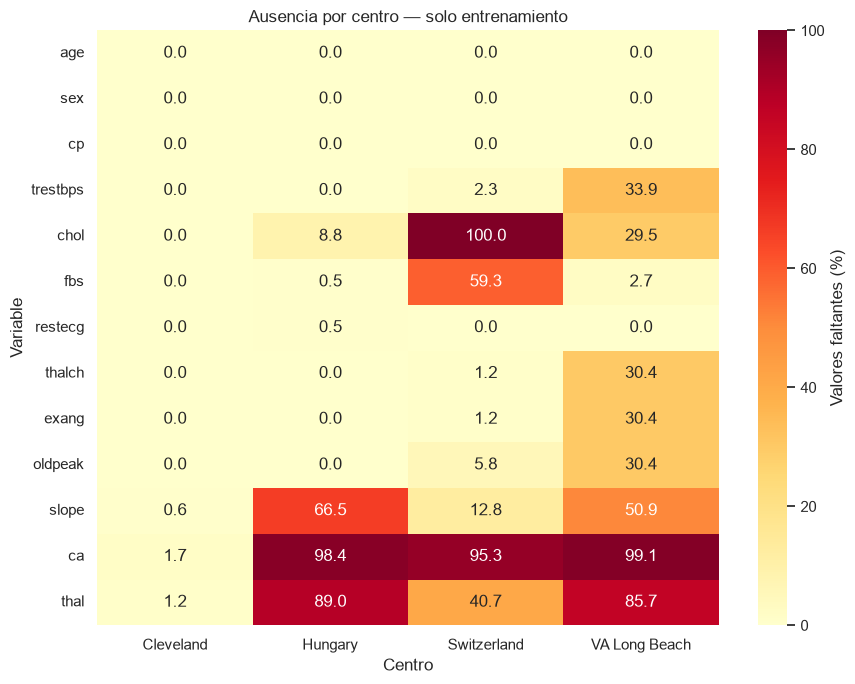

,registros,observados,faltantes
dataset,,,
Cleveland,172,169,3
Hungary,182,3,179
Switzerland,86,4,82
VA Long Beach,112,1,111


**Lee la fila de colesterol de izquierda a derecha.** En entrenamiento falta el 0.0 % en Cleveland y el 100.0 % en Switzerland. Si en una columna de ese centro todo está ausente, no tenemos ninguna observación local con la que calcular su mediana. En ca, usa el conteo de observados de la tabla para distinguir entre una mediana respaldada por muchos registros y otra basada en uno o dos.

In [8]:
missing_summary = pd.DataFrame({
    "faltantes": X_train.isna().sum(),
    "porcentaje": X_train.isna().mean().mul(100),
}).sort_values("porcentaje", ascending=False)
display(missing_summary.round(2))
missing_by_center = X_train.groupby("dataset").agg(lambda s: s.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(missing_by_center.T, annot=True, fmt=".1f", vmin=0, vmax=100,
            cmap="YlOrRd", cbar_kws={"label": "Valores faltantes (%)"}, ax=ax)
ax.set(title="Ausencia por centro — solo entrenamiento", xlabel="Centro", ylabel="Variable")
plt.tight_layout()
plt.show()

availability_ca = X_train.groupby("dataset")["ca"].agg(registros="size", observados="count")
availability_ca["faltantes"] = availability_ca["registros"] - availability_ca["observados"]
display(availability_ca)
display(Markdown(
    f"**Lee la fila de colesterol de izquierda a derecha.** En entrenamiento falta el "
    f"{missing_by_center.loc['Cleveland', 'chol']:.1f} % en Cleveland y el "
    f"{missing_by_center.loc['Switzerland', 'chol']:.1f} % en Switzerland. "
    "Si en una columna de ese centro todo está ausente, no tenemos ninguna observación "
    "local con la que calcular su mediana. En ca, usa el conteo de observados de la tabla "
    "para distinguir entre una mediana respaldada por muchos registros y otra basada en uno o dos."
))


**Decisiones que sí podemos proponer a partir de esto:**

- ca y thal merecen comparar conservación y exclusión: falta una parte grande de su información.
  El porcentaje por sí solo no decide borrarlas.
- Si un centro no tiene colesterol observado, su mediana local no existe. Si solo tiene una
  observación de ca, la mediana local es ese único valor; no la consideramos automáticamente
  una estimación representativa.
- Rellenar una categoría con su moda puede reforzar demasiado una etiqueta. Compararemos
  la moda con una categoría explícita “desconocido”.
- Añadir indicadores de ausencia permite distinguir medición observada y dato rellenado.
  También puede permitir aprender patrones del centro; no demuestra una relación fisiológica.

### ¿Por qué no borrar todas las filas con algún nulo?

El siguiente diagnóstico simula cuántas conservaríamos por centro, sin eliminarlas.
Si casi todas las filas conservadas proceden de un centro, habríamos cambiado la población
evaluada. Una puntuación mayor en esa submuestra no prueba que mejore el modelo para
los registros que excluimos.


In [9]:
row_audit = X_train.assign(
    fila_completa=X_train.notna().all(axis=1),
    nulos_por_fila=X_train.isna().sum(axis=1),
)
row_summary = row_audit.groupby("dataset").agg(
    registros=("fila_completa", "size"),
    filas_completas=("fila_completa", "sum"),
    promedio_nulos=("nulos_por_fila", "mean"),
)
row_summary["porcentaje_conservado_si_borramos"] = (
    100 * row_summary["filas_completas"] / row_summary["registros"]
)
display(row_summary.round(2))


,registros,filas_completas,promedio_nulos,porcentaje_conservado_si_borramos
dataset,,,,
Cleveland,172,168,0.03,97.67
Hungary,182,1,2.64,0.55
Switzerland,86,0,3.19,0.00
VA Long Beach,112,1,3.93,0.89


**Decisión sobre filas.** Si aquí ejecutáramos `dropna()`, quedarían 170 de los 552 registros de entrenamiento. De esos 170, 168 serían de Cleveland y ninguno de Switzerland. Por eso conservamos las filas y comparamos formas de representar los datos ausentes. La decisión sale de contar a quién perderíamos.


## 7. Distribuciones y extremos: detectar no es decidir borrar

Un histograma muestra dónde se concentran los valores y sus colas.
El boxplot resume mediana, mitad central y posibles extremos según sus bigotes.
Un punto exterior no demuestra error de captura.

Calculamos límites de 1.5 IQR para **investigar**, usando únicamente entrenamiento.
La asimetría positiva sugiere una cola hacia valores altos, pero no impone transformar.
No exigimos que las entradas sean normales para usar un árbol, KNN o logística.

**Decisión:** conservar los extremos que no contradicen las reglas anteriores y comparar
escalado robusto y transformación Yeo–Johnson. Esta última admite cero y negativos, por
lo que evita aplicar incorrectamente logaritmos a oldpeak. Para ca conservamos su
representación de conteo; la transformación de forma se aplica a las otras numéricas.


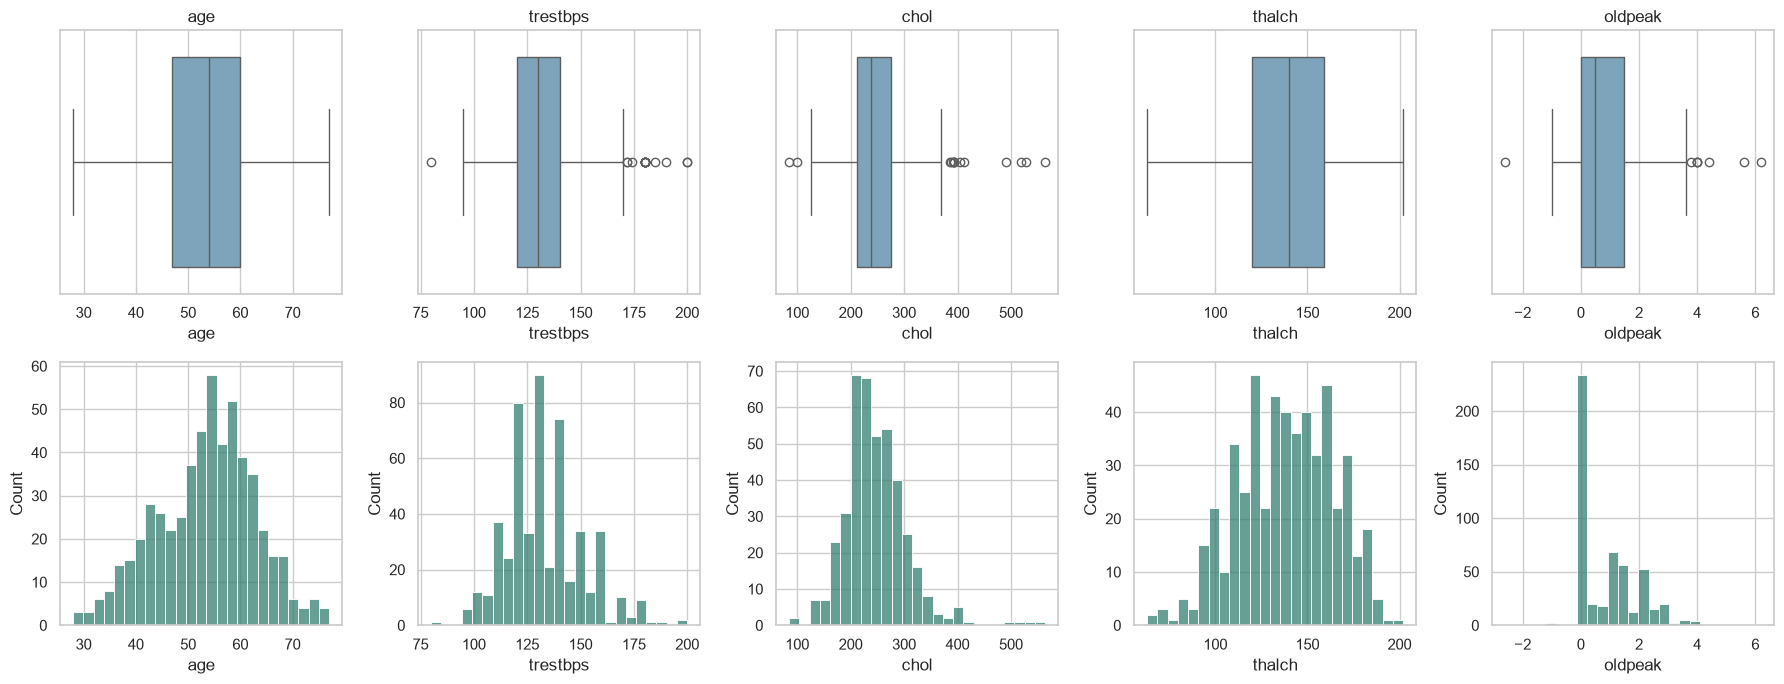

,observados,mínimo,mediana,máximo,límite_inferior_IQR,límite_superior_IQR,fuera_de_límites,asimetría
variable,,,,,,,,
age,552,28.0,54.0,77.0,27.50,79.50,0,-0.20
trestbps,512,80.0,130.0,200.0,89.25,171.25,17,0.58
chol,417,85.0,239.0,564.0,113.50,373.50,14,1.24
thalch,517,63.0,140.0,202.0,61.50,217.50,0,-0.20
oldpeak,513,-2.6,0.5,6.2,-2.25,3.75,8,1.07


In [10]:
continuous_columns = ["age", "trestbps", "chol", "thalch", "oldpeak"]
numeric_columns = continuous_columns + ["ca"]
outlier_rows = []
fig, axes = plt.subplots(2, len(continuous_columns), figsize=(18, 7))
for i, column in enumerate(continuous_columns):
    values = X_train[column].dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "variable": column, "observados": len(values), "mínimo": values.min(),
        "mediana": values.median(), "máximo": values.max(),
        "límite_inferior_IQR": low, "límite_superior_IQR": high,
        "fuera_de_límites": int(((values < low) | (values > high)).sum()),
        "asimetría": values.skew(),
    })
    sns.boxplot(x=values, ax=axes[0, i], color="#73a7c5")
    sns.histplot(values, bins=25, ax=axes[1, i], color="#347f70")
    axes[0, i].set_title(column)
    axes[1, i].set_xlabel(column)
plt.tight_layout()
plt.show()
display(pd.DataFrame(outlier_rows).set_index("variable").round(2))


### Una misma columna antes y después

Observa la fila de histogramas anterior. La altura de una barra cuenta registros en un
intervalo del eje horizontal. En el boxplot la línea marca la mediana, la caja contiene el
50 % central y los puntos aislados merecen inspección. Un colesterol alto puede ser poco
frecuente y proporcionar información.

El profesor coloca dos histogramas juntos para ver el efecto de una transformación.
Aquí usamos exactamente los mismos registros de colesterol observado en ambos paneles.
La línea vertical marca la mediana de cada escala. El panel derecho usa unidades
transformadas. Mira la longitud de la cola derecha respecto al centro. Una cola más
corta sugiere que la transformación cambia cuánto separan los extremos a los registros.
La sección 11 mide el efecto de usar esta familia de transformaciones en el modelo.
[Ejemplo del profesor](../../notebooks/lectures/chapter_03/05_transformacion_y_escalado.ipynb).


Asimetría antes: 1.24 | después: 0.01


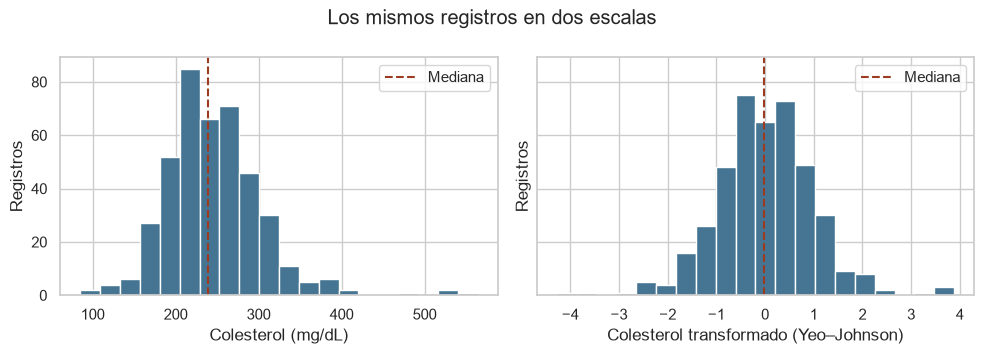

In [11]:
chol_observed = X_train[["chol"]].dropna()
chol_transformed = PowerTransformer().fit_transform(chol_observed).ravel()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, values, unit in zip(axes, [chol_observed["chol"], chol_transformed],
                            ["Colesterol (mg/dL)", "Colesterol transformado (Yeo–Johnson)"]):
    ax.hist(values, bins=20, color="#467594", edgecolor="white")
    ax.axvline(np.median(values), color="#9c3b1f", linestyle="--", label="Mediana")
    ax.set(xlabel=unit, ylabel="Registros")
    ax.legend()
fig.suptitle("Los mismos registros en dos escalas")
fig.tight_layout()
plt.show()
print(f"Asimetría antes: {chol_observed['chol'].skew():.2f} | después: {pd.Series(chol_transformed).skew():.2f}")


**Lectura de los dos histogramas.** En las 417 mediciones observadas, la asimetría del colesterol pasa de 1.24 a 0.01. Se ve en la cola derecha, que ocupa menos espacio en el segundo panel. Esta observación justifica *probar* Yeo–Johnson. Para decidir si mantenerla, compara su F1 con «Ausencia explícita» en la sección 11, donde las demás reglas de preparación coinciden.


## 8. Correlaciones: qué miden y cómo leerlas

Pearson resume la **asociación lineal** de dos variables numéricas:

- Cerca de +1: valores altos de una suelen acompañar valores altos de la otra.
- Cerca de −1: valores altos de una suelen acompañar valores bajos de la otra.
- Cerca de 0: poca asociación lineal; todavía puede existir una relación no lineal.

El signo indica dirección, no “buena” o “mala” variable. Spearman compara rangos y resume
asociación monótona; tampoco detecta todas las relaciones posibles.

### Cómo leer el mapa

Busca el cruce de dos nombres. El número de esa celda es su coeficiente. La diagonal vale
1 porque cada columna se compara consigo misma. El mapa es simétrico; no hay dos evidencias
independientes arriba y abajo de la diagonal. La escala de color aquí va de −1 a +1:
**no representa porcentajes**, a diferencia del mapa de nulos.

Incluimos target en este gráfico de exploración, fuera de X. Para una entrada numérica y
un target 0/1, Pearson es la correlación punto-biserial. Describe una asociación con la
etiqueta; no demuestra que la variable cause enfermedad.

Los nulos se excluyen por pares. La correlación de ca puede basarse en muchos menos casos,
concentrados en Cleveland. Por eso mostraremos también cuántos registros sostienen cada
coeficiente. No rellenamos primero toda la tabla para “hacer más bonito” el mapa.


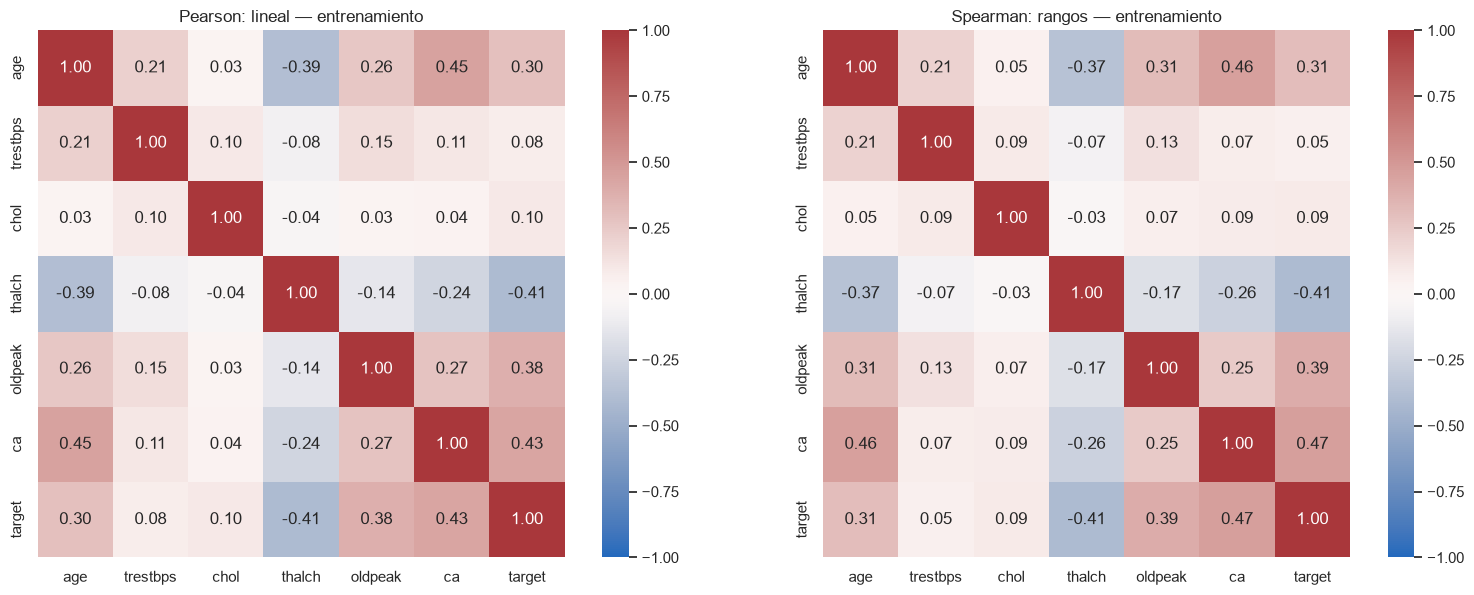

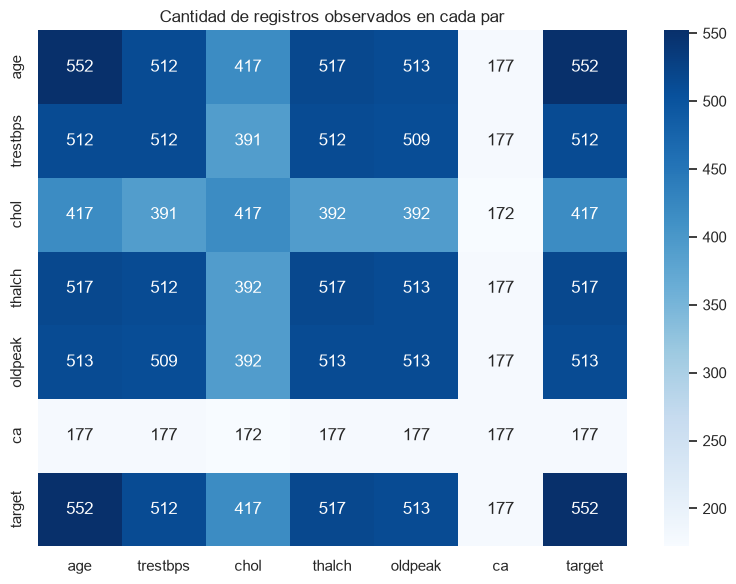

,Pearson_con_target,Spearman_con_target,registros_utilizados
ca,0.433,0.468,177
thalch,-0.413,-0.412,517
oldpeak,0.381,0.392,513
age,0.296,0.311,552
chol,0.096,0.094,417
trestbps,0.077,0.055,512


In [12]:
corr_data = train[numeric_columns + ["target"]]
pearson = corr_data.corr(method="pearson")
spearman = corr_data.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, matrix, title in zip(axes, [pearson, spearman], ["Pearson: lineal", "Spearman: rangos"]):
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                center=0, square=True, ax=ax)
    ax.set_title(title + " — entrenamiento")
plt.tight_layout()
plt.show()

observed = corr_data.notna().astype(int)
pair_counts = observed.T.dot(observed)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pair_counts, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Cantidad de registros observados en cada par")
plt.tight_layout()
plt.show()

target_association = pd.DataFrame({
    "Pearson_con_target": pearson["target"].drop("target"),
    "Spearman_con_target": spearman["target"].drop("target"),
    "registros_utilizados": pair_counts["target"].drop("target"),
})
display(target_association.sort_values("Pearson_con_target", key=lambda s: s.abs(), ascending=False).round(3))


### Del color en el mapa a los registros que lo producen

Busca <code>age × thalch</code> en Pearson y luego observa el diagrama de dispersión.
Cada punto reúne la edad y la frecuencia máxima de un mismo registro de entrenamiento.
Las celdas del mapa resumen esa nube en un número. El color del punto indica el diagnóstico.
Si los colores se mezclan en una región, clasificar solo con esas dos mediciones es difícil allí.
[Dispersión por clase en el notebook del profesor](../../notebooks/lectures/chapter_05/04_regresion_logistica.ipynb).


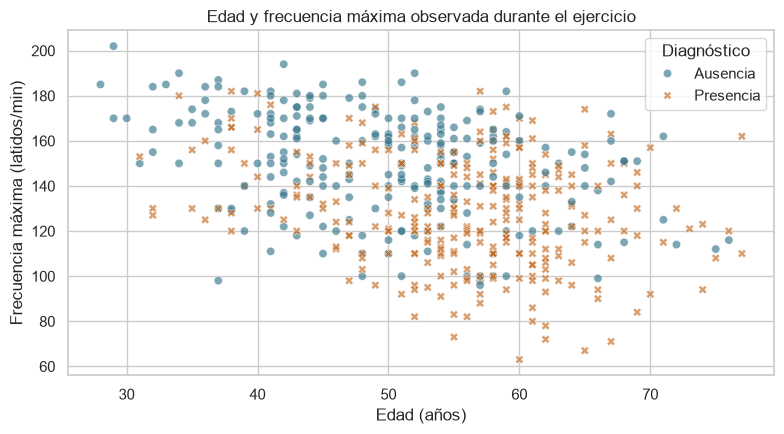

El cruce **age × thalch** vale **-0.39** y utiliza **517 registros**. En esta muestra, las edades mayores tienden a acompañarse de una frecuencia máxima menor. Los puntos dispersos alrededor de esa tendencia explican por qué el coeficiente está lejos de ±1.

In [13]:
points = train[["age", "thalch", "target"]].dropna().copy()
points["Diagnóstico"] = points["target"].map({0: "Ausencia", 1: "Presencia"})
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=points, x="age", y="thalch", hue="Diagnóstico", style="Diagnóstico",
                palette=["#38768c", "#c36a21"], alpha=.65, ax=ax)
ax.set(xlabel="Edad (años)", ylabel="Frecuencia máxima (latidos/min)",
       title="Edad y frecuencia máxima observada durante el ejercicio")
plt.tight_layout()
plt.show()
r_pair = pearson.loc["age", "thalch"]
direction = "menor" if r_pair < 0 else "mayor"
display(Markdown(f"El cruce **age × thalch** vale **{r_pair:.2f}** y utiliza "
                 f"**{len(points)} registros**. En esta muestra, las edades mayores tienden "
                 f"a acompañarse de una frecuencia máxima {direction}. Los puntos dispersos "
                 "alrededor de esa tendencia explican por qué el coeficiente está lejos de ±1."))


In [14]:
strongest = target_association["Pearson_con_target"].abs().idxmax()
r = target_association.loc[strongest, "Pearson_con_target"]
n = int(target_association.loc[strongest, "registros_utilizados"])
display(Markdown(
    f"**Lectura concreta:** entre estas numéricas, **{strongest}** tiene el mayor valor "
    f"absoluto de Pearson con target: **{r:.3f}**, calculado con **{n} registros observados**. "
    "Esto orienta la exploración; no seleccionamos automáticamente solo esa columna "
    "ni descartamos las demás."
))

redundant_pairs = []
features_corr = pearson.drop(index="target", columns="target")
for i, first in enumerate(features_corr.columns):
    for second in features_corr.columns[i + 1:]:
        value = features_corr.loc[first, second]
        if abs(value) >= .80:
            redundant_pairs.append({"variable_1": first, "variable_2": second, "Pearson": value})
display(pd.DataFrame(redundant_pairs, columns=["variable_1", "variable_2", "Pearson"]))
if not redundant_pairs:
    print("No hay pares de estas entradas con |Pearson| >= 0.80.")


No hay pares de estas entradas con |Pearson| >= 0.80.


**Lectura concreta:** entre estas numéricas, **ca** tiene el mayor valor absoluto de Pearson con target: **0.433**, calculado con **177 registros observados**. Esto orienta la exploración; no seleccionamos automáticamente solo esa columna ni descartamos las demás.

,variable_1,variable_2,Pearson


### Dos preguntas diferentes: utilidad y redundancia

**Entrada frente a target:** buscamos señales para predecir. Una correlación baja no
justifica borrar: la variable puede funcionar mediante umbrales, interacciones o una
relación curva. KNN y los árboles pueden aprovechar patrones que Pearson no resume.

**Entrada frente a otra entrada:** buscamos posible redundancia. Dos columnas con
correlación alta pueden repetir parte de la información. En logística eso puede volver
inestables los coeficientes; la regularización puede ayudar. En KNN puede aumentar el peso
de una misma dimensión de información. Para decidir quitar una, comparamos alternativas
con CV; un umbral 0.80 es una señal de revisión, no una ley.

**Correlación no es causalidad.** Una relación puede deberse al centro, a selección de
pacientes o a otra variable. Además, introducir num haría que el mapa pareciera muy
predictivo porque contiene el diagnóstico; esa sería fuga de información.

### Un ejemplo donde correlación cero no significa “inútil”

En el ejemplo inventado siguiente, conocer x determina exactamente y=x². Pearson es cero
por simetría y la relación es curva. El gráfico revela lo que un único coeficiente oculta.


Pearson del ejemplo inventado: 0.0


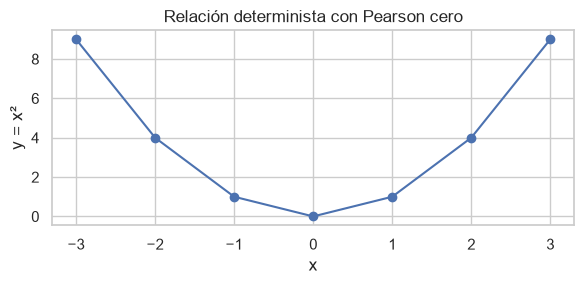

In [15]:
x_example = np.arange(-3, 4)
y_example = x_example ** 2
print("Pearson del ejemplo inventado:", round(np.corrcoef(x_example, y_example)[0, 1], 3))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x_example, y_example, "o-")
ax.set(xlabel="x", ylabel="y = x²", title="Relación determinista con Pearson cero")
plt.tight_layout()
plt.show()


## 9. Relacionar las entradas con el objetivo

Mirar solo distribuciones globales no muestra si los valores separan las clases.
Comparamos cada numérica por target en entrenamiento. Si hay mucho solapamiento,
una variable por sí sola probablemente no separe perfectamente los casos; aun así
puede ayudar combinada con otras.

En ca, observamos conteos; el boxplot es una descripción compacta y no convierte el
conteo en continuo. La frecuencia por valor completa su interpretación.


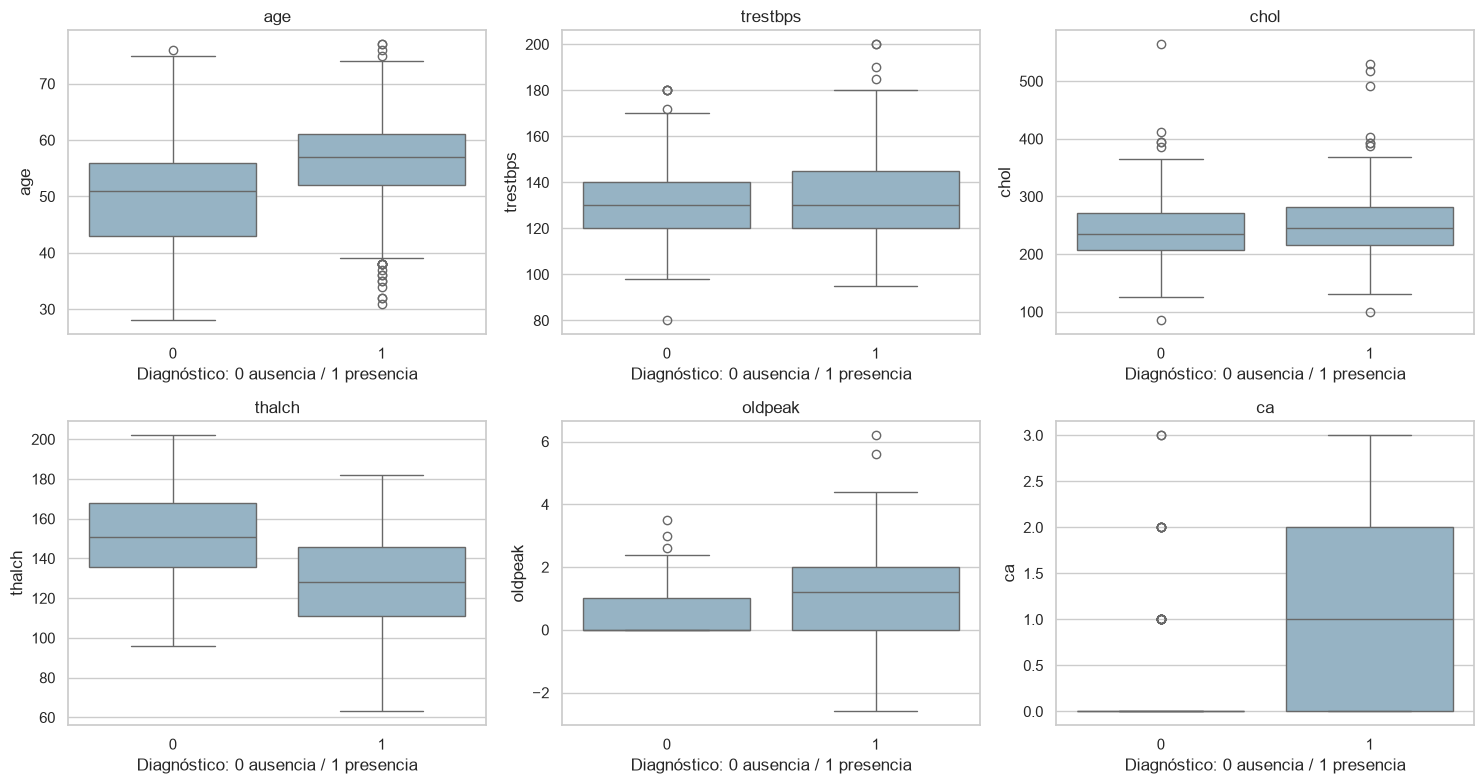

target,0,1
ca,,
0.0,0.750,0.250
1.0,0.308,0.692
2.0,0.250,0.750
3.0,0.200,0.800


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(data=train, x="target", y=column, ax=ax, color="#8eb5cc")
    ax.set_title(column)
    ax.set_xlabel("Diagnóstico: 0 ausencia / 1 presencia")
plt.tight_layout()
plt.show()
display(pd.crosstab(train["ca"], train["target"], normalize="index").round(3))


**Lectura por clase.** Compara primero las líneas centrales de las cajas y después la zona en que se solapan. La tabla de abajo concreta lo que se observa en `ca`. Entre los casos con cero vasos registrados, 25 % tienen etiqueta positiva. Entre quienes tienen tres, la proporción es 80 %. Estos porcentajes describen solo los casos que sí tienen medición de `ca`. El mapa de faltantes explica por qué generalizar esa diferencia a los cuatro centros sería arriesgado.


### Las categorías necesitan otra exploración

No convertimos cp en 0,1,2,3 para calcular una correlación: el resultado dependería del
orden inventado de esos números. En lugar de eso mostramos conteos y proporción de
target=1 por categoría.

Una barra alta significa una mayor proporción observada de positivos dentro de ese grupo.
Una categoría con pocos casos puede tener una proporción extrema por poca evidencia;
por eso revisamos también su tamaño. “Sin dato” describe ausencia, no un diagnóstico.

One-hot crea una columna por etiqueta sin imponer una distancia ordinal. En KNN, esa
codificación influye en las distancias; no es un proceso neutro.


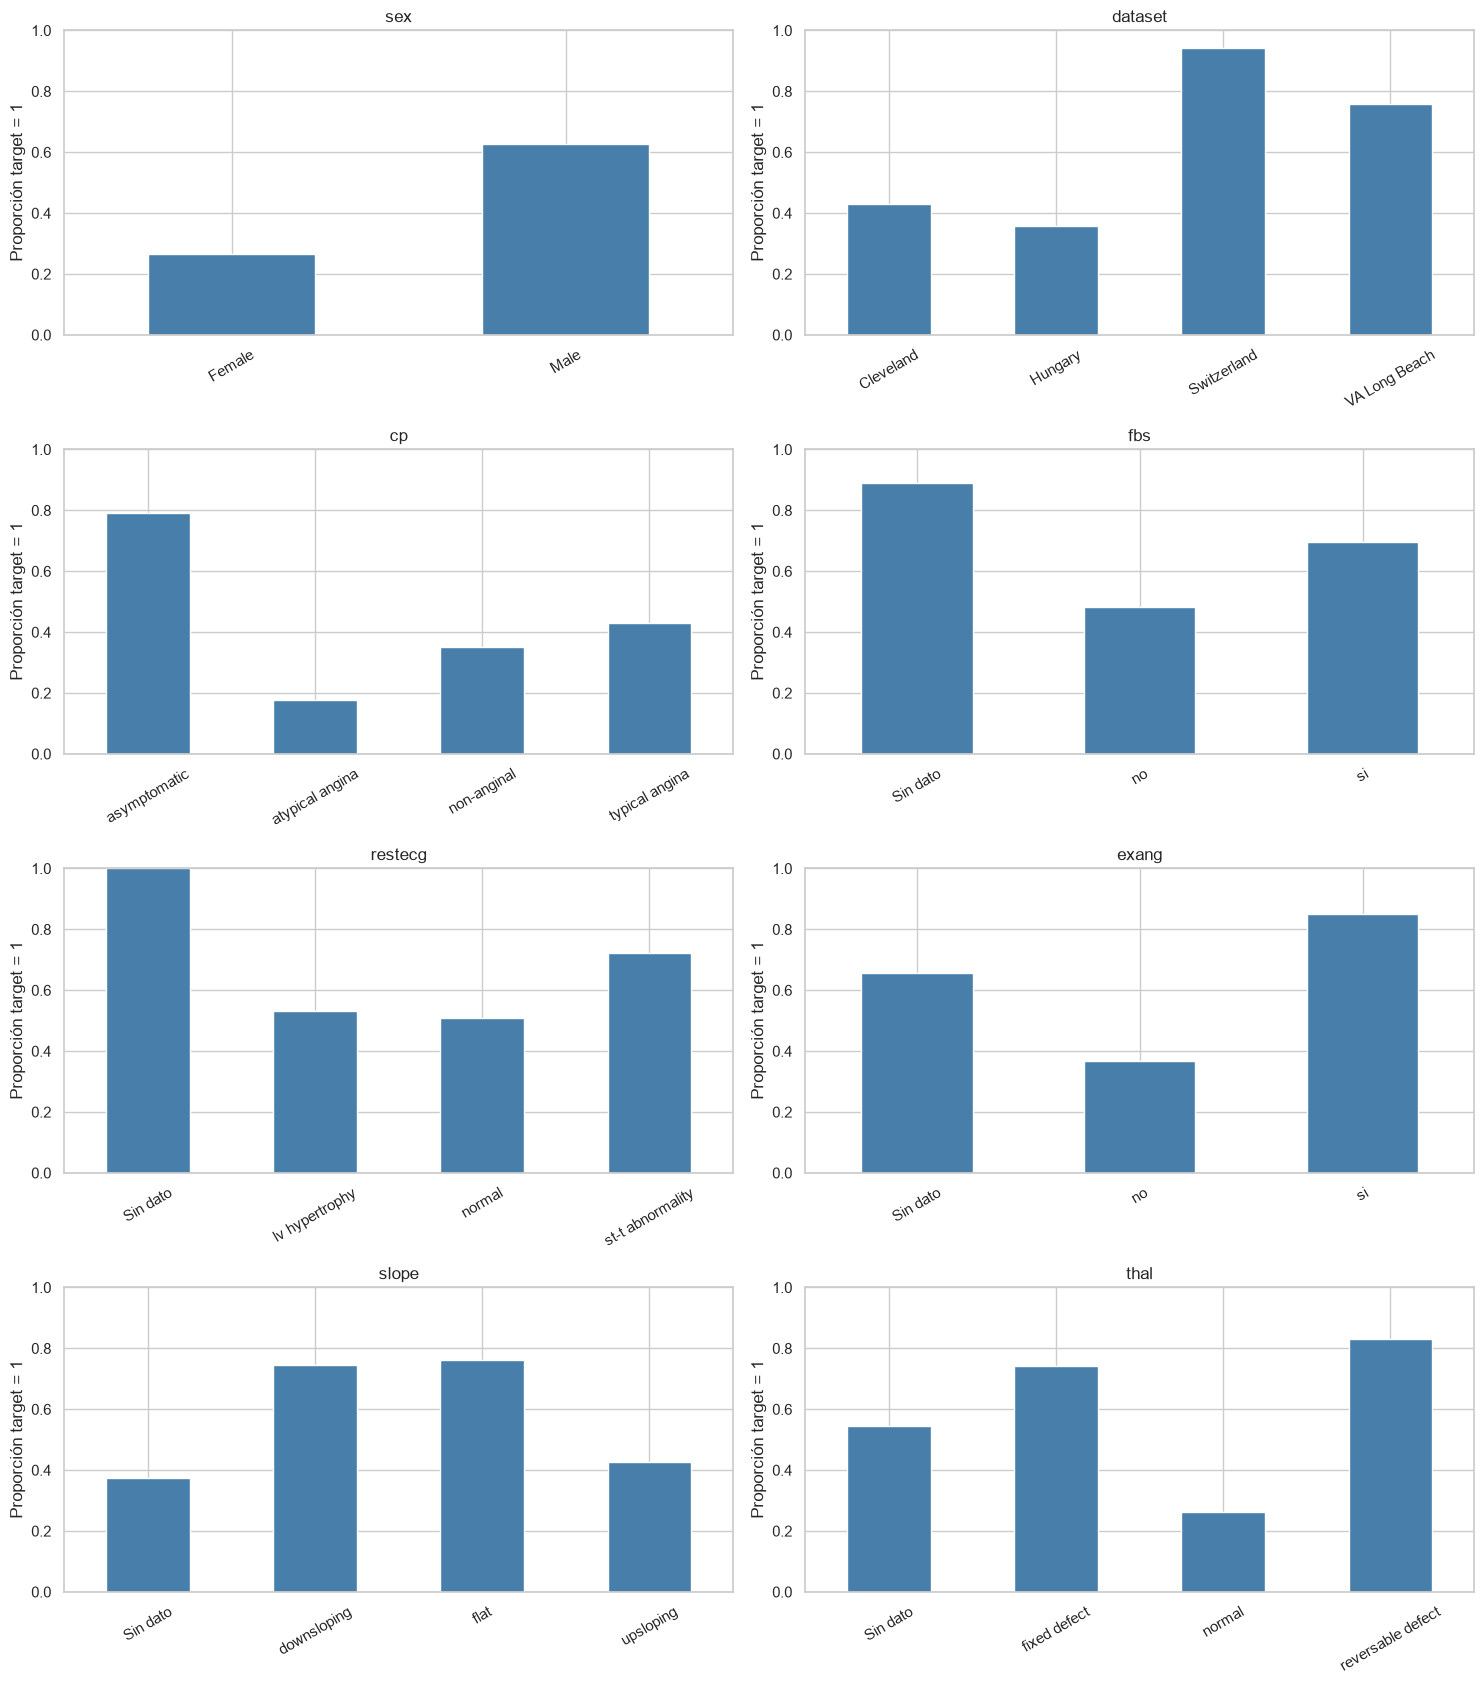

,registros,proporcion_positivos
categoria,,
Cleveland,172,0.430
Hungary,182,0.357
Switzerland,86,0.942
VA Long Beach,112,0.759


,registros,proporcion_positivos
categoria,,
Sin dato,295,0.546
fixed defect,27,0.741
normal,118,0.263
reversable defect,112,0.830


In [17]:
fig, axes = plt.subplots(4, 2, figsize=(15, 17))
category_summaries = {}
for ax, column in zip(axes.flat, categorical_columns):
    category = train[column].fillna("Sin dato")
    summary = train.assign(categoria=category).groupby("categoria")["target"].agg(
        registros="size", proporcion_positivos="mean"
    )
    category_summaries[column] = summary
    summary["proporcion_positivos"].plot.bar(ax=ax, color="#487eaa")
    ax.set_title(column)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Proporción target = 1")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()
display(category_summaries["dataset"].round(3))
display(category_summaries["thal"].round(3))


**Ejemplo de las barras.** En `thal`, la barra «normal» representa 26.3 % de positivos entre 118 registros. Para «reversable defect» son 83.0 % entre 112. En «Sin dato» son 54.6 % entre 295. Rellenar esas 295 filas con «normal» reuniría dos grupos con composiciones diferentes bajo una misma etiqueta. De ahí sale una alternativa concreta para probar en los tres modelos: conservar «desconocido» como categoría.


## 10. Convertir observaciones en alternativas que se puedan evaluar

Hasta aquí describimos los datos. Ahora definimos candidatos antes de mirar sus resultados.
No prometemos que todos mejoren; la comparación es la forma de descartar propuestas.

| Candidato | Qué cambia | Razón y coste posible |
|---|---|---|
| Base | Mediana numérica, moda categórica; escala estándar para logística/KNN | Referencia sencilla; mezcla observados e imputados sin señal explícita |
| Ausencia explícita | Mediana, categoría desconocido e indicadores numéricos | Distingue falta de medición; puede aprender prácticas del centro |
| Escala robusta | Mismo tratamiento de ausencia, escalado por mediana/IQR | Reduce la influencia de extremos sobre la escala; no elimina extremos |
| Forma Yeo–Johnson | Transforma las numéricas continuas después de imputar | Comprime/asocia su forma sin exigir positividad; cambia distancias y relaciones lineales |
| Sin ca | Ausencia explícita, excluyendo ca | Evita depender de tantos rellenos; pierde mediciones útiles |
| Sin ca y thal | Excluye ambas columnas de alta ausencia | Simplifica; puede perder señal importante |
| Sin origen | Excluye dataset | Comprueba dependencia del centro explícito; otros patrones aún pueden revelar origen |
| Imputación por vecinos | Escala y estima numéricas usando registros parecidos | Aprovecha relaciones; puede fallar con poca información compartida y cuesta más |

Los cambios combinados de “ausencia explícita” evalúan una política conjunta. No atribuimos
su resultado a un único componente. Las exclusiones ca, ca+thal y origen se comparan
con esa misma política, para identificar su coste adicional.

El mejor tratamiento puede ser distinto por algoritmo. Para el árbol no repetimos las
variantes de escala robusta y Yeo–Johnson: los cambios monótonos no justifican una nueva
búsqueda de escala para sus umbrales. La imputación por vecinos sí escala porque necesita
distancias, aunque el predictor final sea un árbol.

**No borramos filas ni extremos para hacer el test más fácil.** Todos los candidatos se
evalúan sobre los mismos registros de sus particiones.


In [18]:
preparations = {
    "Base": dict(imputation="median", category="mode", indicator=False, scale="standard", drop=[]),
    "Ausencia explícita": dict(imputation="median", category="unknown", indicator=True, scale="standard", drop=[]),
    "Escala robusta": dict(imputation="median", category="unknown", indicator=True, scale="robust", drop=[]),
    "Forma Yeo-Johnson": dict(imputation="median", category="unknown", indicator=True, scale="power", drop=[]),
    "Sin ca": dict(imputation="median", category="unknown", indicator=True, scale="standard", drop=["ca"]),
    "Sin ca y thal": dict(imputation="median", category="unknown", indicator=True, scale="standard", drop=["ca", "thal"]),
    "Sin origen": dict(imputation="median", category="unknown", indicator=True, scale="standard", drop=["dataset"]),
    "Imputación por vecinos": dict(imputation="neighbors", category="unknown", indicator=True, scale="standard", drop=[]),
}

def build_numeric_pipeline(config, model_name, is_count=False):
    # Antes de KNNImputer se escala sin rellenar: así las unidades no dominan sus vecinos.
    if config["imputation"] == "neighbors":
        return Pipeline([
            ("scale", StandardScaler()),
            ("imputer", KNNImputer(n_neighbors=5, weights="distance")),
        ])
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_name != "Árbol":
        if config["scale"] == "power" and not is_count:
            steps.append(("shape", PowerTransformer(method="yeo-johnson", standardize=True)))
        elif config["scale"] == "robust":
            steps.append(("scale", RobustScaler()))
        else:
            steps.append(("scale", StandardScaler()))
    return Pipeline(steps)

def build_preprocessor(config, model_name):
    continuous = [c for c in continuous_columns if c not in config["drop"]]
    counts = [c for c in ["ca"] if c not in config["drop"]]
    categorical = [c for c in categorical_columns if c not in config["drop"]]
    imputer = (
        SimpleImputer(strategy="most_frequent")
        if config["category"] == "mode"
        else SimpleImputer(strategy="constant", fill_value="desconocido")
    )
    branches = [
        ("continuous", build_numeric_pipeline(config, model_name), continuous),
        ("categorical", Pipeline([
            ("imputer", imputer),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
    ]
    if counts:
        branches.append(("counts", build_numeric_pipeline(config, model_name, is_count=True), counts))
    if config["imputation"] == "neighbors":
        # Estimar ca también a partir de las otras mediciones requiere pasarlas juntas.
        branches = [
            ("numeric", build_numeric_pipeline(config, model_name), continuous + counts),
            branches[1],
        ]
    if config["indicator"]:
        # Conservar las señales 0/1 sin transformarlas con Yeo–Johnson ni escalarlas.
        branches.append(("missing", MissingIndicator(features="all"), continuous + counts))
    return ColumnTransformer(branches, remainder="drop", sparse_threshold=0)

estimators = {
    "Logística": LogisticRegression(max_iter=3000, random_state=SEED),
    "KNN": KNeighborsClassifier(),
    "Árbol": DecisionTreeClassifier(random_state=SEED),
}
parameter_grids = {
    "Logística": {"model__C": [.01, .1, 1, 10], "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": [5, 11, 15, 21],
            "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    "Árbol": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 10],
              "model__class_weight": [None, "balanced"]},
}


### Qué aprende cada herramienta y cuándo

- SimpleImputer aprende medianas o modas con el entrenamiento de ese fold.
- StandardScaler aprende media y desviación; RobustScaler aprende mediana y cuantiles.
- PowerTransformer aprende una transformación por columna; también debe ajustarse dentro.
- OneHotEncoder aprende las categorías observadas. Una categoría nueva se gestiona con
  handle_unknown, sin ajustar otro codificador al conjunto que estamos evaluando.
- MissingIndicator conserva la ausencia original. Aquí los indicadores permanecen 0/1.
- KNNImputer estima entradas; KNeighborsClassifier predice el diagnóstico. Comparten
  la idea de vecinos, pero son tareas distintas.

Pipeline y ColumnTransformer organizan estos pasos. No mejoran por su nombre: permiten
aprender referencias donde corresponde y aplicarlas de forma consistente.

## 11. Buscar configuraciones con entrenamiento y CV

Cada búsqueda ajusta preparación y modelo dentro de cada fold. Comparamos la media F1
y su desviación entre folds. Esa desviación describe variación entre estos repartos;
no es automáticamente un intervalo de confianza.

La mejor preparación de cada algoritmo se elige por CV. **Validación todavía no se usa
para elegir entre los ocho tratamientos.** Después compararemos los tres finalistas en ella.
Los espacios de hiperparámetros son los mismos para todas las preparaciones de un algoritmo.
Así no favorecemos una preparación dándole una búsqueda más amplia.


In [19]:
searches = {}
experiment_rows = []
start = time.perf_counter()
for model_name, estimator in estimators.items():
    for preparation_name, config in preparations.items():
        if model_name == "Árbol" and preparation_name in ["Escala robusta", "Forma Yeo-Johnson"]:
            continue
        pipeline = Pipeline([
            ("preprocessor", build_preprocessor(config, model_name)),
            ("model", clone(estimator)),
        ])
        search = GridSearchCV(
            pipeline, parameter_grids[model_name],
            scoring="f1", cv=cv_splits, n_jobs=N_JOBS,
            refit=True, return_train_score=True, error_score="raise",
        )
        search.fit(X_train, y_train)
        searches[(model_name, preparation_name)] = search
        best = search.best_index_
        experiment_rows.append({
            "modelo": model_name, "preparación": preparation_name,
            "F1_CV": search.best_score_,
            "desviación_CV": search.cv_results_["std_test_score"][best],
            "parámetros": search.best_params_,
        })
        print(f"{model_name:10} | {preparation_name:24} | F1 CV = {search.best_score_:.3f}", flush=True)

experiments = pd.DataFrame(experiment_rows)
baseline_scores = experiments.loc[experiments["preparación"].eq("Base")].set_index("modelo")["F1_CV"]
experiments["cambio_frente_base_CV"] = experiments["F1_CV"] - experiments["modelo"].map(baseline_scores)
print(f"Tiempo de búsqueda: {time.perf_counter() - start:.1f} segundos")
display(experiments.sort_values(["modelo", "F1_CV"], ascending=[True, False]).round(4))


Logística  | Base                     | F1 CV = 0.850
Logística  | Ausencia explícita       | F1 CV = 0.855
Logística  | Escala robusta           | F1 CV = 0.859
Logística  | Forma Yeo-Johnson        | F1 CV = 0.859
Logística  | Sin ca                   | F1 CV = 0.846
Logística  | Sin ca y thal            | F1 CV = 0.839
Logística  | Sin origen               | F1 CV = 0.853
Logística  | Imputación por vecinos   | F1 CV = 0.855
KNN        | Base                     | F1 CV = 0.869
KNN        | Ausencia explícita       | F1 CV = 0.862
KNN        | Escala robusta           | F1 CV = 0.863
KNN        | Forma Yeo-Johnson        | F1 CV = 0.863
KNN        | Sin ca                   | F1 CV = 0.855
KNN        | Sin ca y thal            | F1 CV = 0.852
KNN        | Sin origen               | F1 CV = 0.856
KNN        | Imputación por vecinos   | F1 CV = 0.854
Árbol      | Base                     | F1 CV = 0.789
Árbol      | Ausencia explícita       | F1 CV = 0.790
Árbol      | Sin ca         

,modelo,preparación,F1_CV,desviación_CV,parámetros,cambio_frente_base_CV
8,KNN,Base,0.8689,0.0278,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.0000
10,KNN,Escala robusta,0.8634,0.0202,"{'model__n_neighbors': 5, 'model__p': 2, 'mode...",-0.0056
11,KNN,Forma Yeo-Johnson,0.8627,0.0161,"{'model__n_neighbors': 5, 'model__p': 1, 'mode...",-0.0062
9,KNN,Ausencia explícita,0.8615,0.0186,"{'model__n_neighbors': 21, 'model__p': 1, 'mod...",-0.0074
14,KNN,Sin origen,0.8556,0.0173,"{'model__n_neighbors': 5, 'model__p': 1, 'mode...",-0.0133
12,KNN,Sin ca,0.8550,0.0131,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",-0.0140
15,KNN,Imputación por vecinos,0.8537,0.0220,"{'model__n_neighbors': 21, 'model__p': 1, 'mod...",-0.0152
13,KNN,Sin ca y thal,0.8517,0.0091,"{'model__n_neighbors': 21, 'model__p': 2, 'mod...",-0.0172
2,Logística,Escala robusta,0.8591,0.0163,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.0086
3,Logística,Forma Yeo-Johnson,0.8586,0.0124,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.0081


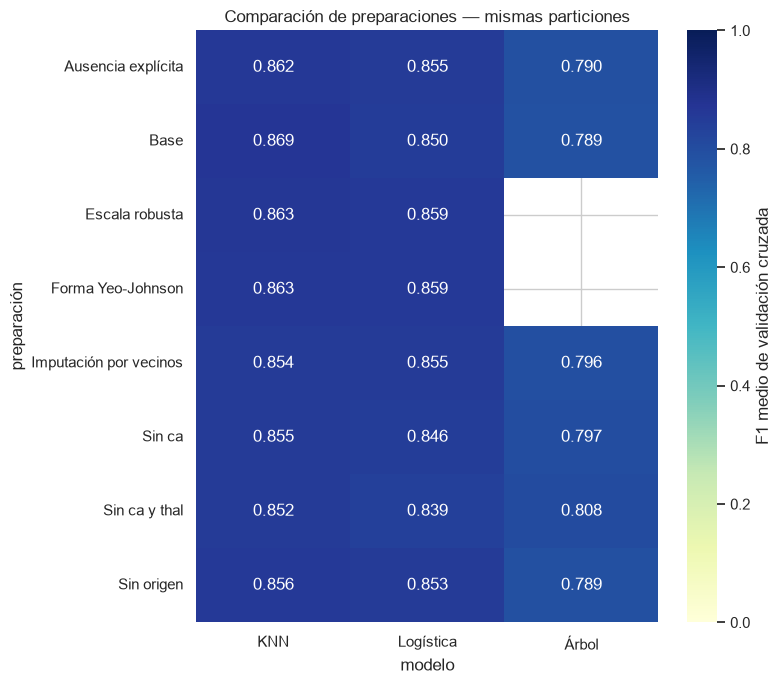

In [20]:
cv_map = experiments.pivot(index="preparación", columns="modelo", values="F1_CV")
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(cv_map, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 medio de validación cruzada"})
ax.set_title("Comparación de preparaciones — mismas particiones")
plt.tight_layout()
plt.show()


**Decisión trabajada de principio a fin: ¿quitamos `ca`?** De 552 registros de entrenamiento, solo 177 traen esa medición, y 169 de ellos proceden de Cleveland. Su correlación de Pearson con el diagnóstico es +0.433 en esos 177 casos. Hay razones tanto para conservar la medición como para revisar la dependencia de ese centro.

En el mapa de F1 compara las filas **Ausencia explícita** y **Sin ca**. En cada una se volvieron a buscar los hiperparámetros con los mismos folds. Para logística, quitarla cambia el F1 medio de 0.855 a 0.846. Para KNN cambia de 0.862 a 0.855. Para el árbol cambia de 0.790 a 0.797. Con esta política, conservarla funciona mejor en los dos primeros y excluirla ayuda ligeramente al árbol. Al excluir también `thal`, el árbol alcanza 0.808. Las diferencias son pequeñas y se refieren a estos repartos.


**Cómo leer este tercer mapa de calor:** ahora cada número es F1 medio de CV, no una
correlación ni un porcentaje de nulos. Un hueco en el árbol corresponde a una preparación
que decidimos no buscar por ser una repetición de escala innecesaria.

Mira la columna de un modelo para comparar tratamientos. Una mejora de unas milésimas
merece prudencia, especialmente si es menor que la variación entre folds. Una variante
que pierde frente a Base sigue siendo un resultado útil: permite rechazar una propuesta.
La mejor media entre muchas búsquedas puede ser optimista; validación aporta otra comprobación.


In [21]:
# Orden estable: en un empate exacto se conserva la primera alternativa de menor índice.
best_rows = experiments.loc[experiments.groupby("modelo", sort=False)["F1_CV"].idxmax()].copy()
finalists = {
    row["modelo"]: searches[(row["modelo"], row["preparación"])].best_estimator_
    for _, row in best_rows.iterrows()
}
validation_rows = []
for _, row in best_rows.iterrows():
    name = row["modelo"]
    model = finalists[name]
    validation_rows.append({
        "modelo": name, "preparación": row["preparación"],
        "F1_entrenamiento": f1_score(y_train, model.predict(X_train)),
        "F1_CV": row["F1_CV"], "desviación_CV": row["desviación_CV"],
        "F1_validación": f1_score(y_val, model.predict(X_val)),
        "parámetros": row["parámetros"],
    })
validation_results = pd.DataFrame(validation_rows).set_index("modelo")
selected_name = validation_results.sort_values(
    ["F1_validación", "F1_CV"], ascending=False
).index[0]
display(validation_results.round(4))
print("Modelo seleccionado ANTES de evaluar prueba:", selected_name)


Modelo seleccionado ANTES de evaluar prueba: KNN


,preparación,F1_entrenamiento,F1_CV,desviación_CV,F1_validación,parámetros
modelo,,,,,,
Logística,Escala robusta,0.8609,0.8591,0.0163,0.8406,"{'model__C': 0.01, 'model__class_weight': 'bal..."
KNN,Base,0.8780,0.8689,0.0278,0.8505,"{'model__n_neighbors': 11, 'model__p': 1, 'mod..."
Árbol,Sin ca y thal,0.8543,0.8079,0.0304,0.8100,"{'model__class_weight': None, 'model__max_dept..."


### Dos gráficas de clase para entender las configuraciones elegidas

En la **curva de KNN**, el eje horizontal indica cuántos vecinos votan y el vertical muestra F1.
Comparamos las medias de entrenamiento y de los folds reservados en cada vuelta manteniendo
fijos la preparación, los pesos y la distancia de la configuración elegida. La separación
entre las curvas muestra cuánto cambia el resultado al pasar a otros registros.
[Curva por número de vecinos del profesor](../../notebooks/lectures/chapter_05/06_knn_clasificacion_y_regresion.ipynb).


Con k=11 y pesos uniform, el F1 medio en los folds reservados es 0.869.


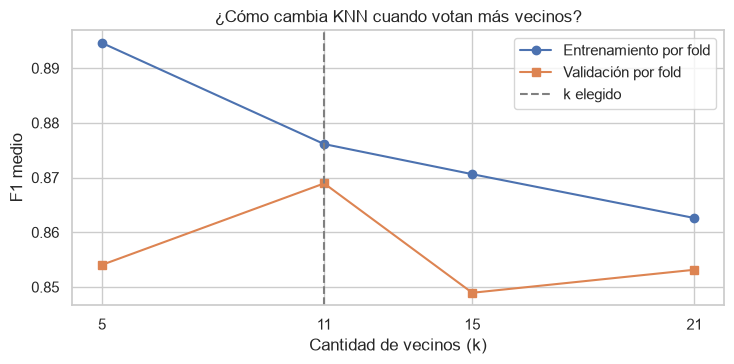

In [22]:
knn_search = searches[("KNN", validation_results.loc["KNN", "preparación"])]
best_knn = knn_search.best_params_
knn_curve = pd.DataFrame(knn_search.cv_results_)
knn_curve = knn_curve.loc[
    knn_curve["param_model__weights"].eq(best_knn["model__weights"]) &
    knn_curve["param_model__p"].eq(best_knn["model__p"])
].sort_values("param_model__n_neighbors")
ks = knn_curve["param_model__n_neighbors"].astype(int)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ks, knn_curve["mean_train_score"], "o-", label="Entrenamiento por fold")
ax.plot(ks, knn_curve["mean_test_score"], "s-", label="Validación por fold")
ax.axvline(best_knn["model__n_neighbors"], linestyle="--", color="gray", label="k elegido")
ax.set(xlabel="Cantidad de vecinos (k)", ylabel="F1 medio", xticks=ks,
       title="¿Cómo cambia KNN cuando votan más vecinos?")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Con k={best_knn['model__n_neighbors']} y pesos {best_knn['model__weights']}, "
      f"el F1 medio en los folds reservados es {knn_search.best_score_:.3f}.")


En el **árbol**, empieza en el recuadro superior y lee la primera condición. Si se cumple
sigues la rama izquierda. Si no, la derecha. La clase escrita en cada nodo es la que
predomina allí según los pesos del modelo. El color indica esa clase y la intensidad su predominio.
Una regla de una columna one-hot compara un indicador 0/1. Por ejemplo, un umbral de 0.5
separa ausencia y presencia de esa categoría. Mostramos solo los dos primeros niveles de
división para poder leer el recorrido. Los puntos suspensivos indican que continúa.
[Dibujo del árbol en clase](../../notebooks/lectures/chapter_05/05_arboles_clasificacion_y_regresion.ipynb).


Primera pregunta del árbol: ¿categorical__cp_asymptomatic ≤ 0.50?


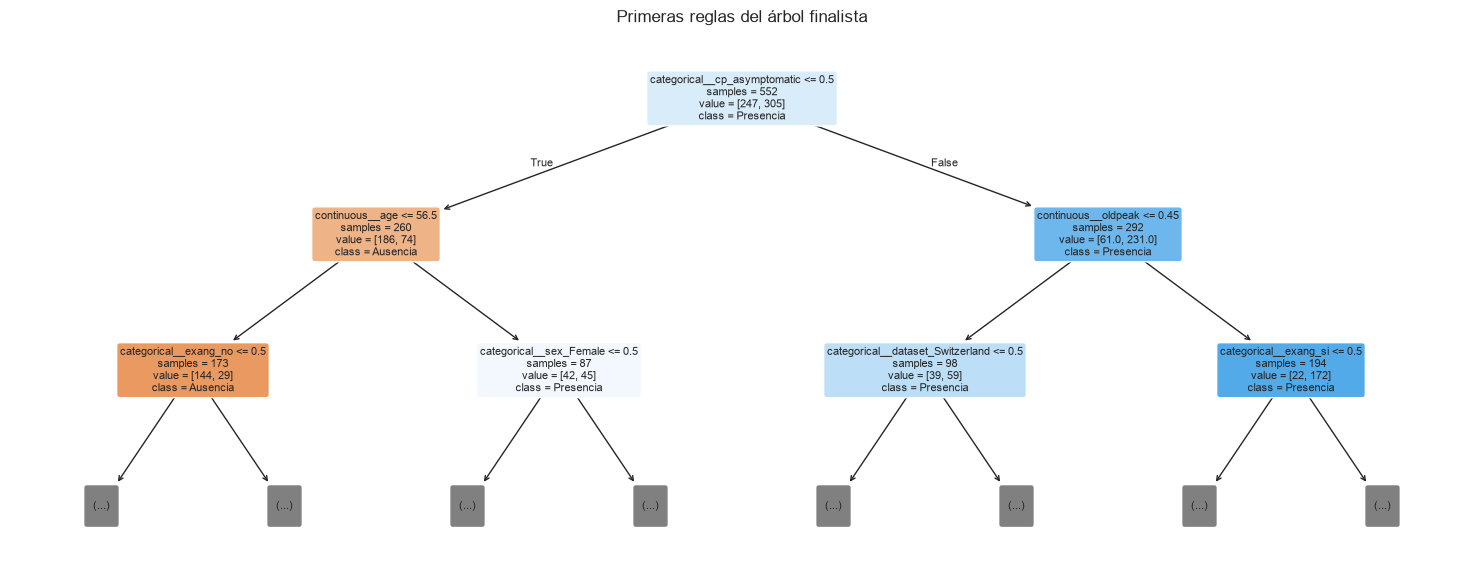

In [23]:
tree_pipeline = finalists["Árbol"]
tree_model = tree_pipeline.named_steps["model"]
feature_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(tree_model, max_depth=2, feature_names=feature_names, class_names=["Ausencia", "Presencia"],
          filled=True, rounded=True, impurity=False, precision=2, fontsize=8, ax=ax)
ax.set_title("Primeras reglas del árbol finalista")
plt.tight_layout()
plt.show()
root_feature = feature_names[tree_model.tree_.feature[0]]
cut = tree_model.tree_.threshold[0]
print(f"Primera pregunta del árbol: ¿{root_feature} ≤ {cut:.2f}?")


**Sigue una fila real por la primera regla.** El nodo raíz pregunta si el indicador de dolor torácico «asymptomatic» vale como máximo 0.50. Un registro de esa categoría tiene indicador 1 y va a la derecha. Uno de otra categoría tiene indicador 0 y va a la izquierda. El nodo siguiente indica qué otra característica distingue el árbol dentro de ese grupo.


In [24]:
for _, row in best_rows.iterrows():
    name, prep = row["modelo"], row["preparación"]
    change = row["F1_CV"] - baseline_scores[name]
    removed = preparations[prep]["drop"]
    display(Markdown(
        f"**{name}: {prep}.** F1 medio de CV = **{row['F1_CV']:.3f}**, "
        f"cambio frente a su Base = **{change:+.3f}**. "
        f"Columnas originales excluidas por esta preparación: **{', '.join(removed) if removed else 'ninguna adicional'}**. "
        "La elección se apoya en esta comparación y en las hipótesis de la sección 10; "
        "no demuestra que el método sea universalmente superior."
    ))


**Logística: Escala robusta.** F1 medio de CV = **0.859**, cambio frente a su Base = **+0.009**. Columnas originales excluidas por esta preparación: **ninguna adicional**. La elección se apoya en esta comparación y en las hipótesis de la sección 10; no demuestra que el método sea universalmente superior.

**KNN: Base.** F1 medio de CV = **0.869**, cambio frente a su Base = **+0.000**. Columnas originales excluidas por esta preparación: **ninguna adicional**. La elección se apoya en esta comparación y en las hipótesis de la sección 10; no demuestra que el método sea universalmente superior.

**Árbol: Sin ca y thal.** F1 medio de CV = **0.808**, cambio frente a su Base = **+0.019**. Columnas originales excluidas por esta preparación: **ca, thal**. La elección se apoya en esta comparación y en las hipótesis de la sección 10; no demuestra que el método sea universalmente superior.

## 12. Revisar sobreajuste y utilidad de las variables

La tabla anterior compara entrenamiento, CV y validación. Un F1 alto en entrenamiento con
una caída relevante fuera de él puede indicar ajuste a particularidades de la muestra.
Con KNN y pesos por distancia, un registro de entrenamiento suele tenerse a sí mismo
como vecino de distancia cero: F1=1 en entrenamiento tiene una explicación mecánica
y no demuestra capacidad de generalizar.

### Importancia por permutación: otra pregunta distinta de correlación

Tomamos un finalista ya entrenado y desordenamos una entrada de validación. Si F1 cae,
ese modelo dependía de la información de esa columna en estos registros. Medimos la
caída media sobre diez repeticiones.

Esto permite inspeccionar entradas nominales y efectos no lineales sin inventar códigos
para calcular Pearson. No demuestra causalidad ni prescribe borrar todas las columnas
con valor cercano a cero. Variables correlacionadas pueden sustituirse y ocultar importancia
individual; la variación de las repeticiones también importa.

Esta inspección es explicativa. La selección anterior queda fijada y no seguimos
retocando tratamientos según el test.


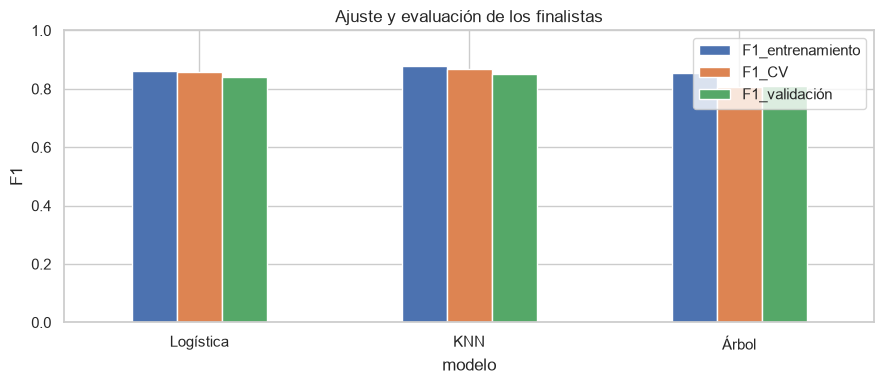

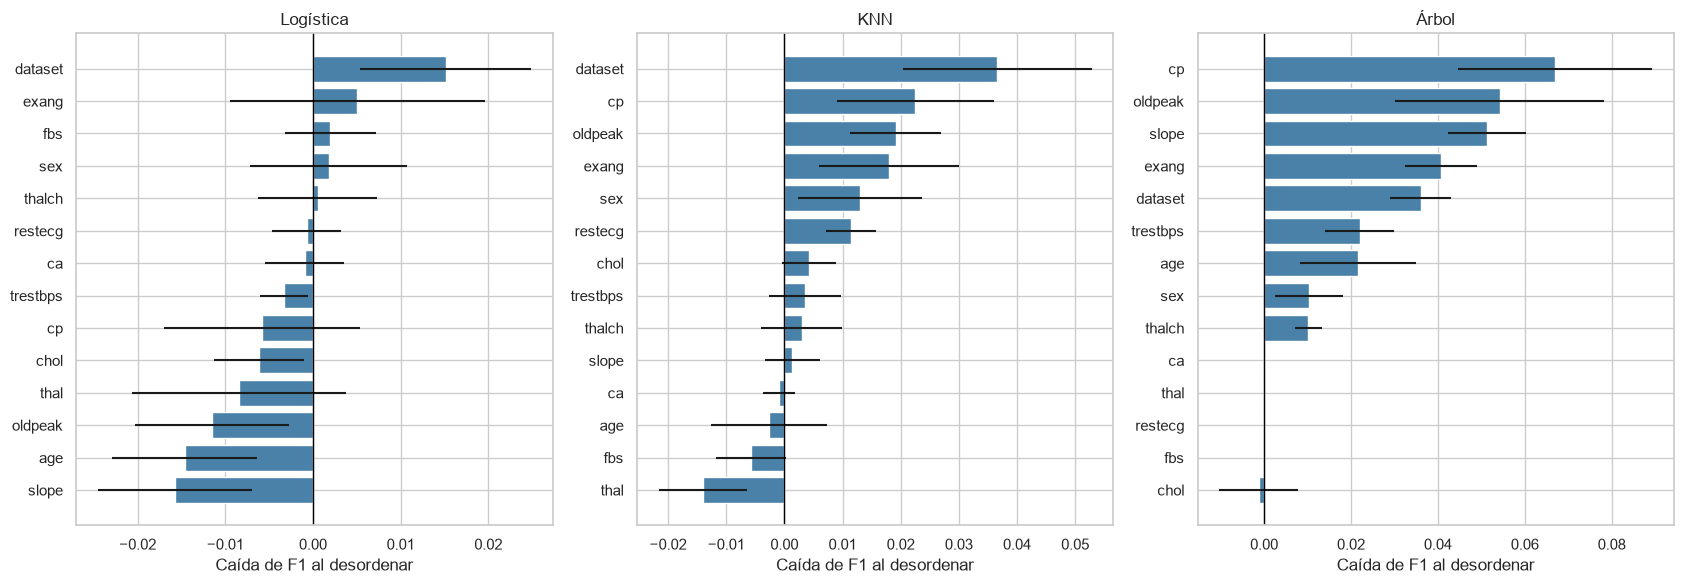

,caída_media_F1,desviación
dataset,0.0366,0.0162
cp,0.0225,0.0135
oldpeak,0.0191,0.0078
exang,0.0180,0.0120
sex,0.0130,0.0107
restecg,0.0115,0.0042
chol,0.0042,0.0047
trestbps,0.0036,0.0062
thalch,0.0030,0.0069
slope,0.0014,0.0047


In [25]:
validation_results[["F1_entrenamiento", "F1_CV", "F1_validación"]].plot.bar(
    figsize=(9, 4), ylim=(0, 1), rot=0
)
plt.title("Ajuste y evaluación de los finalistas")
plt.ylabel("F1")
plt.tight_layout()
plt.show()

importance_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, model) in zip(axes, finalists.items()):
    importance = permutation_importance(
        model, X_val, y_val, scoring="f1", n_repeats=10,
        random_state=SEED, n_jobs=N_JOBS,
    )
    table = pd.DataFrame({
        "caída_media_F1": importance.importances_mean,
        "desviación": importance.importances_std,
    }, index=X_val.columns).sort_values("caída_media_F1")
    importance_tables[name] = table
    ax.barh(table.index, table["caída_media_F1"], xerr=table["desviación"], color="#4a81a8")
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=name, xlabel="Caída de F1 al desordenar")
plt.tight_layout()
plt.show()
display(importance_tables[selected_name].sort_values("caída_media_F1", ascending=False).round(4))


**Cómo interpretar las barras.** En el gráfico de desempeño, el árbol pasa de F1 0.854 en entrenamiento a 0.810 en validación. En las barras horizontales de KNN, desordenar el centro reduce F1 en 0.037 de media. Las líneas finas muestran la variación entre repeticiones. En esta muestra el clasificador utiliza el origen para predecir. Eso merece atención si después queremos evaluar pacientes de otro centro.


## 13. Evaluación final de prueba: configuraciones ya fijadas

Ahora evaluamos una vez los tres finalistas para completar la comparación del proyecto.
Se entrenaron sobre entrenamiento; no se reajustan al llegar test. El modelo recomendado
ya fue seleccionado por validación. Si otro obtiene mejor test, no cambiamos la elección
usando ese resultado.

**Cómo leer las métricas:**

| Métrica | Pregunta |
|---|---|
| Accuracy | ¿Qué proporción total se clasificó correctamente? |
| Balanced accuracy | ¿Cuál es el promedio del recall de ambas clases? |
| Precisión | De los predichos positivos, ¿cuántos eran positivos? |
| Recall | De los positivos reales, ¿cuántos detectamos? |
| F1 | ¿Qué equilibrio hay entre precisión y recall de la clase positiva? |
| ROC AUC | ¿Qué capacidad de ordenar positivos por encima de negativos tienen los puntajes? |

F1 y AUC no equivalen a porcentaje de aciertos. La utilidad de los errores depende del uso;
para este proyecto justificamos F1 como compromiso y mostramos los errores por separado.


In [26]:
test_predictions = {}
test_probabilities = {}
test_rows = []
for name, model in finalists.items():
    predictions = model.predict(X_test)
    positive_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_test)[:, positive_column]
    test_predictions[name] = predictions
    test_probabilities[name] = probabilities
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_rows.append({
        "modelo": name,
        "preparación": validation_results.loc[name, "preparación"],
        "F1_entrenamiento": validation_results.loc[name, "F1_entrenamiento"],
        "F1_validación": validation_results.loc[name, "F1_validación"],
        "F1_prueba": f1_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "precisión": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
    })
test_results = pd.DataFrame(test_rows).set_index("modelo")
display(test_results.round(4))


,preparación,F1_entrenamiento,F1_validación,F1_prueba,accuracy,balanced_accuracy,precisión,recall,ROC_AUC,VN,FP,FN,VP
modelo,,,,,,,,,,,,,
Logística,Escala robusta,0.8609,0.8406,0.7980,0.7826,0.7836,0.8229,0.7745,0.8904,65,17,23,79
KNN,Base,0.8780,0.8505,0.8286,0.8043,0.7984,0.8056,0.8529,0.8859,61,21,15,87
Árbol,Sin ca y thal,0.8543,0.8100,0.7923,0.7663,0.7617,0.7810,0.8039,0.8101,59,23,20,82


### Matrices de confusión

**Filas = realidad; columnas = predicción.** La diagonal contiene aciertos.
Arriba a la derecha están los falsos positivos: ausencia real predicha como presencia.
Abajo a la izquierda están los falsos negativos: presencia real predicha como ausencia.
Usamos el mismo orden 0,1 y la misma escala de color en los tres gráficos.


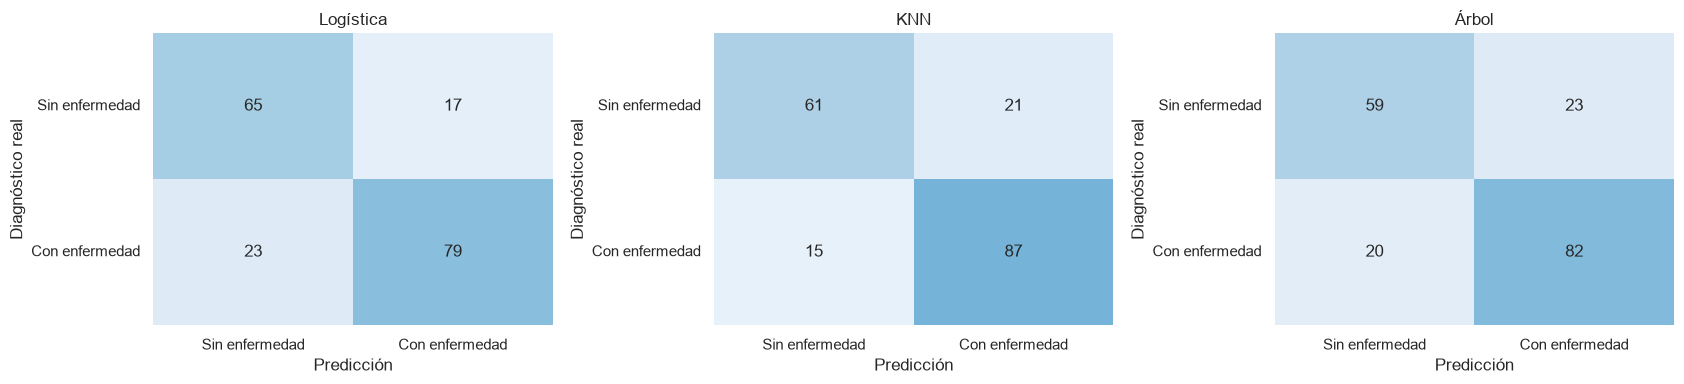

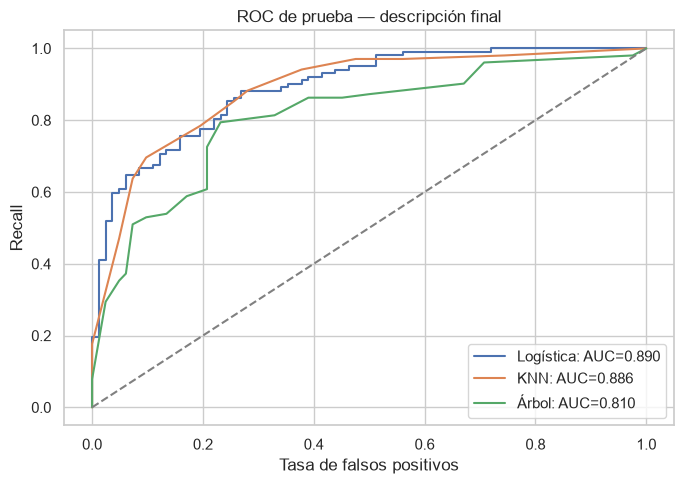

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
class_names = ["Sin enfermedad", "Con enfermedad"]
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                vmin=0, vmax=len(y_test), xticklabels=class_names,
                yticklabels=class_names, ax=ax)
    ax.set(title=name, xlabel="Predicción", ylabel="Diagnóstico real")
    ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name}: AUC={test_results.loc[name, 'ROC_AUC']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Recall",
       title="ROC de prueba — descripción final")
ax.legend()
plt.tight_layout()
plt.show()


**Lee la matriz de KNN siguiendo la fila inferior.** Había 102 positivos reales. El modelo detectó 87 y clasificó a 15 como negativos. El recall resulta de dividir 87 entre 102 (85.3 %). En la fila superior hay 21 falsas alarmas entre 82 negativos reales. Así puedes traducir el color de las celdas a errores concretos.

**Cómo leer la curva ROC.** Cada punto corresponde a un umbral de decisión. La altura es la fracción de positivos detectados y el eje horizontal es la fracción de negativos que producen falsa alarma. Hacia la esquina superior izquierda, se detectan más positivos con menos falsas alarmas. La diagonal sirve de referencia para una ordenación al azar. Logística obtiene el AUC mayor, 0.890, mientras KNN fue elegido por F1 en validación. Son preguntas distintas: el AUC resume el orden de los puntajes a través de umbrales y el F1 evalúa las clases que efectivamente predijo el modelo.


## 14. Recomendación y decisiones justificadas con resultados

La siguiente conclusión se construye con las salidas reales, sin inventar una puntuación
objetivo. Distingue cómo elegimos, qué errores aparecen y qué límites conserva el estudio.


In [28]:
chosen = test_results.loc[selected_name]
display(Markdown(
    f"### Modelo recomendado dentro de este experimento: {selected_name}\n\n"
    f"Se seleccionó por **F1 de validación = {chosen['F1_validación']:.3f}**, "
    f"después de elegir su preparación **{chosen['preparación']}** mediante CV. "
    f"En prueba obtiene **F1 = {chosen['F1_prueba']:.3f}**, "
    f"accuracy = **{chosen['accuracy']:.3f}**, precisión = **{chosen['precisión']:.3f}** "
    f"y recall = **{chosen['recall']:.3f}**.\n\n"
    f"De {len(y_test)} registros de prueba, cometió **{int(chosen['FP'])} falsos positivos** "
    f"y **{int(chosen['FN'])} falsos negativos**; acertó "
    f"**{int(chosen['VN'])} negativos** y **{int(chosen['VP'])} positivos**. "
    "Estos errores deben considerarse junto con su puntuación, no ocultarse detrás de un único número."
))


### Modelo recomendado dentro de este experimento: KNN

Se seleccionó por **F1 de validación = 0.850**, después de elegir su preparación **Base** mediante CV. En prueba obtiene **F1 = 0.829**, accuracy = **0.804**, precisión = **0.806** y recall = **0.853**.

De 184 registros de prueba, cometió **21 falsos positivos** y **15 falsos negativos**; acertó **61 negativos** y **87 positivos**. Estos errores deben considerarse junto con su puntuación, no ocultarse detrás de un único número.

### Qué hace útil esta preparación

- Las correcciones tienen una justificación por variable y dejan trazabilidad.
- Se conservan las filas al comparar tratamientos, evitando cambiar silenciosamente la población.
- Las coincidencias de perfiles se mantienen juntas en separación y CV.
- Las categorías binarias se normalizan sin mezclar booleanos y la cadena desconocido.
- Las transformaciones se ajustan dentro de cada fold; no usan estadísticas del test.
- Se comparan exclusiones de columnas y formas de representar ausencia con una referencia común.
- El tratamiento final se elige por algoritmo: una misma receta no tiene por qué ganar en los tres.

### Qué limita la conclusión

La muestra es pequeña, retrospectiva y procede de pocos centros con patrones de ausencia
distintos. Algunas entradas podrían estar informando sobre el centro o sobre cómo se hicieron
las pruebas. Excluir dataset no elimina necesariamente esa información indirecta.
Los grupos controlan perfiles idénticos, no personas identificadas mediante un identificador
clínico fiable. El reparto no evalúa generalización a centros completamente nuevos.

Las muchas comparaciones pueden favorecer por azar una configuración. Las diferencias pequeñas
no demuestran superioridad estadística. Se buscó entre opciones concretas, no entre todos los
preprocesamientos posibles. Este CSV y resultados de test ya eran conocidos en la sesión;
una validación externa requeriría datos realmente nuevos.

Los resultados respaldan una recomendación académica dentro de este protocolo. No constituyen
una validación para usar el modelo como sistema diagnóstico.

## 15. Cómo decidir qué quitar en otro proyecto

| Lo que encuentras | Lo que puedes concluir | Cómo tomar la decisión |
|---|---|---|
| Identificador arbitrario | No describe una característica disponible con significado predictivo generalizable | Excluir de X; conservar para auditoría |
| Columna que revela la respuesta | Hay fuga de información | Excluir antes de entrenar |
| Valor imposible según definición/unidad | La medición necesita corrección | Corregir con trazabilidad o marcar como ausente |
| Muchos nulos | Hay poca información observada y posible dependencia de grupos | Comparar conservar, indicar ausencia y excluir |
| Correlación baja con target | Hay poca asociación lineal observada | Explorar curvas, categorías e interacciones; no borrar automáticamente |
| Correlación alta entre entradas | Posible redundancia en esta muestra | Revisar significado y comparar exclusión/regularización con CV |
| Puntos fuera del boxplot | Son extremos según una regla estadística | Investigar; conservar si son plausibles y comparar tratamientos robustos |
| Poca importancia por permutación | El modelo concreto no depende mucho de esa entrada aquí | Revisar variación y redundancia antes de proponer una exclusión |
| Mayor puntuación al borrar casos difíciles | Cambió el conjunto evaluado | Comparar sobre el mismo conjunto y explicar la población que se pierde |

**Un registro de decisión útil tiene cuatro partes:** observación, consecuencia posible,
alternativa propuesta y resultado de una comparación válida. Por ejemplo: ca tiene mucha
ausencia; imputarla podría ocultar diferencias; proponemos excluirla o indicar ausencia;
la tabla de CV muestra si esa propuesta ayudó a cada algoritmo.

## Fuentes para volver a estudiar

- [UCI: definición de las variables](https://archive.ics.uci.edu/dataset/45/heart+disease).
- [Tus guías de pandas](https://app.notion.com/p/40581a767e17810c9250fe1e0809f10d),
  [preprocesamiento](https://app.notion.com/p/40581a767e1781c6889cc8052ab2802a),
  [evaluación](https://app.notion.com/p/40b81a767e17815abdfbcccb86a08092)
  y [KNN](https://app.notion.com/p/40b81a767e178199af46c209a41a8b82).
- [pandas: correlaciones y tratamiento de pares observados](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
- [scikit-learn: evitar fuga](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [Separación estratificada con grupos](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
- [Imputación e indicadores de ausencia](https://scikit-learn.org/stable/modules/impute.html).
- [Escalado y transformaciones](https://scikit-learn.org/stable/modules/preprocessing.html).
- [Importancia por permutación y sus límites](https://scikit-learn.org/stable/modules/permutation_importance.html).

### Ejemplos del profesor que dieron origen a estas figuras

- [Dispersión, barras y mapa de correlación del capítulo 3](../../notebooks/lectures/chapter_03/03_matplotlib.ipynb).
- [Boxplot e histograma para investigar extremos](../../notebooks/lectures/chapter_03/04_limpieza_y_outliers.ipynb).
- [Distribución antes y después de transformar](../../notebooks/lectures/chapter_03/05_transformacion_y_escalado.ipynb).
- [Clases y matrices de confusión en clasificación](../../notebooks/lectures/chapter_05/04_regresion_logistica.ipynb).
- [Primeras reglas de un árbol](../../notebooks/lectures/chapter_05/05_arboles_clasificacion_y_regresion.ipynb).
- [Curva de KNN al variar los vecinos](../../notebooks/lectures/chapter_05/06_knn_clasificacion_y_regresion.ipynb).
